# Evaluation: which backbone works best for independent crop + disease CNNs?

**Setup in one line:** for each backbone, one CNN predicts the **crop** (55 classes) and a separate CNN predicts
the **disease** (175 classes). A composition (crop + disease pair, 333 candidates) is scored as
log p(crop) + log p(disease). **Seen test** = 2000 images of pairs that appear in training;
**unseen test** = 1448 images of 10 pairs that never appear in training.

**How to read this notebook**

| Section | Question it answers |
|---|---|
| 1 | Were all backbones trained the same way? |
| 2 | **Which backbone wins?** (scoreboard, verdict with confidence intervals) |
| 3 | Does the ranking change if we allow 5 guesses instead of 1? |
| 4 | How much does training help over the untouched ImageNet weights? |
| 5 | What does each backbone cost (size, training time, speed)? |
| 6-12 | Why the models behave as they do (per-model detail, errors, unseen pairs, class imbalance) |

Everything is computed from the saved results in `runs/`; nothing is retrained. Re-run all cells after new runs.

In [12]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from IPython.display import display, Markdown
from PIL import Image
from common import read_csv, candidate_comps, comp_scores

METHOD_DIRS = {"fine-tuned": Path("runs/main"), "frozen": Path("runs/frozen")}  # frozen = linear_probe.py --save_runs
IMG_DIR = Path("DPD_Small_Dataset")
BACKBONES = ["efficientnet_b0", "resnet50", "convnext_tiny", "efficientnet_b3"]  # fixed order = fixed colours
NAME = {"efficientnet_b0": "EfficientNet-B0", "resnet50": "ResNet-50",
        "convnext_tiny": "ConvNeXt-Tiny", "efficientnet_b3": "EfficientNet-B3"}
WEIGHTS = {"efficientnet_b0": "ImageNet-1K V1", "resnet50": "ImageNet-1K V2",
           "convnext_tiny": "ImageNet-1K V1", "efficientnet_b3": "ImageNet-1K V1"}  # torchvision weights="DEFAULT"
COLOR = dict(zip(BACKBONES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
METRICS = ["seen_top1", "unseen_top1", "harmonic_top1", "seen_top5", "unseen_top5", "harmonic_top5"]
LABEL = {"seen_top1": "Seen Top-1", "unseen_top1": "Unseen Top-1", "harmonic_top1": "Harmonic Top-1",
         "seen_top5": "Seen Top-5", "unseen_top5": "Unseen Top-5", "harmonic_top5": "Harmonic Top-5"}
FT = "fine-tuned"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
})

tr, se, un = (read_csv(f"DPD_Small_{s}.csv") for s in ("train", "test_seen", "test_unseen"))
comp_ids, crop_idx, dis_idx = candidate_comps(tr, se, un)
comp_name = pd.concat([tr, se, un]).drop_duplicates("comp").set_index("comp")["comp_name"]
dis_name = pd.concat([tr, se, un]).drop_duplicates("disease").set_index("disease")["disease_name"]


def bar_labels(ax, bars, fmt="{:.3f}", size=8):
    for b in bars:
        ax.annotate(fmt.format(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=size, color=INK2)


def grouped_bars(ax, groups, values, backbones, ylim=(0, 1.08)):
    'values[bb] = list aligned with groups; one bar per backbone inside each group.'
    w = 0.8 / len(backbones); x = np.arange(len(groups))
    for i, bb in enumerate(backbones):
        bars = ax.bar(x + (i - (len(backbones) - 1) / 2) * w, values[bb], w,
                      color=COLOR[bb], edgecolor=SURFACE, linewidth=2, label=NAME[bb])
        bar_labels(ax, bars)
    ax.set_xticks(x, groups); ax.set_ylim(*ylim); ax.tick_params(axis="x", colors=INK2)


def top_legend(fig, ax, ncol=4, top=0.92):
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.legend(*ax.get_legend_handles_labels(), loc="upper center", ncol=ncol)

In [13]:
rows = []
for method, d in METHOD_DIRS.items():
    for f in sorted(d.glob("*/results.json")):
        r = json.loads(f.read_text()); a = r["args"]
        h = pd.DataFrame(r.get("history", []))
        rows.append({"method": method, "backbone": a["backbone"], "task": a["task"], "val_top1": r["best_val_top1"],
                     "seen_top1": r["seen_top1"], "seen_top5": r["seen_top5"],
                     "unseen_top1": r["unseen_top1"], "unseen_top5": r["unseen_top5"],
                     "params_M": r.get("params_M"), "img_size": r.get("img_size"),
                     "sec_per_epoch": h["sec"].mean() if "sec" in h else np.nan,
                     "train_min": h["sec"].sum() / 60 if "sec" in h else np.nan,
                     "args": a, "history": h, "dir": f.parent})
runs = pd.DataFrame(rows)
assert len(runs), "no finished runs found"

# if a backbone/task was trained more than once, keep the run with the best validation score
best = (runs.sort_values("val_top1", ascending=False)
            .drop_duplicates(["method", "backbone", "task"]).set_index(["method", "backbone", "task"]))
have = lambda m, b: (m, b, "crop") in best.index and (m, b, "disease") in best.index
present = [b for b in BACKBONES if have(FT, b)]
frozen_present = [b for b in BACKBONES if have("frozen", b)]
print("fine-tuned backbones:", [NAME[b] for b in present])
print("frozen baselines:    ", [NAME[b] for b in frozen_present] or "none (run linear_probe.py --save_runs runs/frozen)")

# backbone used for the single-model analyses at the end: best mean validation Top-1 (never chosen on test data)
BEST = max(present, key=lambda b: best.loc[(FT, b, "crop"), "val_top1"] + best.loc[(FT, b, "disease"), "val_top1"])
print("single-model analyses use:", NAME[BEST])

fine-tuned backbones: ['EfficientNet-B0', 'ResNet-50', 'ConvNeXt-Tiny', 'EfficientNet-B3']
frozen baselines:     ['EfficientNet-B0', 'ResNet-50', 'ConvNeXt-Tiny', 'EfficientNet-B3']
single-model analyses use: ConvNeXt-Tiny


## 1. Were all backbones trained the same way?

Every backbone starts from torchvision's ImageNet-1K weights and is then **fine-tuned**: all layers are trained on
our images (the ImageNet weights are only the starting point). **No hyperparameters were tuned**: every run uses
the same `train.py` defaults. The table below is read from each run's saved settings, so it shows what was
actually used.

In [14]:
SETTINGS = ["epochs", "lr", "wd", "bs", "label_smooth", "aug", "freeze_epochs", "seed"]
setup = pd.DataFrame({NAME[b]: {"pretrained weights": WEIGHTS[b],
                                "image size": int(best.loc[(FT, b, "crop"), "img_size"]),
                                **{k: best.loc[(FT, b, "crop"), "args"][k] for k in SETTINGS}} for b in present}).T
display(setup)

same_tasks = all({k: best.loc[(FT, b, "crop"), "args"][k] for k in SETTINGS} ==
                 {k: best.loc[(FT, b, "disease"), "args"][k] for k in SETTINGS} for b in present)
differs = [c for c in setup.columns if setup[c].nunique() > 1]
print("crop and disease runs use identical settings:", same_tasks)
print("settings that differ between backbones:", differs or "none")
print("(image size: each backbone uses its native ImageNet resolution, 300px for EfficientNet-B3, 224px otherwise)")

,pretrained weights,image size,epochs,lr,wd,bs,label_smooth,aug,freeze_epochs,seed
EfficientNet-B0,ImageNet-1K V1,224,15,0.0003,0.0001,32,0.1,strong,0,42
ResNet-50,ImageNet-1K V2,224,15,0.0003,0.0001,32,0.1,strong,0,42
ConvNeXt-Tiny,ImageNet-1K V1,224,15,0.0003,0.0001,32,0.1,strong,0,42
EfficientNet-B3,ImageNet-1K V1,300,15,0.0003,0.0001,32,0.1,strong,0,42


crop and disease runs use identical settings: True
settings that differ between backbones: ['pretrained weights', 'image size']
(image size: each backbone uses its native ImageNet resolution, 300px for EfficientNet-B3, 224px otherwise)


## 2. Scoreboard: which backbone wins?

Composition accuracy for each fine-tuned backbone. **Harmonic** = harmonic mean of seen and unseen accuracy,
the project's headline metric: it is only high if a model does well on *both*.

Each number has a **95% confidence interval** from a paired bootstrap (the test images are resampled 2000 times,
the same resample for every backbone). If two backbones' gap could plausibly be zero, they are reported as **tied**:
with one training run each, small differences are not evidence that one is better.

In [15]:
pos = {c: i for i, c in enumerate(comp_ids)}
S, R = {}, {}   # S = composition scores; R = rank of the true composition (0 = top guess)
for method, bbs in [(FT, present), ("frozen", frozen_present)]:
    for bb in bbs:
        for split, df in [("seen", se), ("unseen", un)]:
            s = comp_scores(np.load(best.loc[(method, bb, "crop"), "dir"] / f"probs_{split}.npy"),
                            np.load(best.loc[(method, bb, "disease"), "dir"] / f"probs_{split}.npy"),
                            crop_idx, dis_idx)
            y = np.array([pos[c] for c in df["comp"]])
            R[method, bb, split] = (s > s[np.arange(len(y)), y][:, None]).sum(1)
            if method == FT:
                S[bb, split] = s

B = 2000
rng = np.random.default_rng(0)
IDX = {"seen": rng.integers(0, len(se), (B, len(se))), "unseen": rng.integers(0, len(un), (B, len(un)))}
hm = lambda s, u: np.where(s + u > 0, 2 * s * u / np.maximum(s + u, 1e-12), 0.0)

point, boot = {}, {}
for key in [(FT, b) for b in present] + [("frozen", b) for b in frozen_present]:
    p, bs = {}, {}
    for k in (1, 5):
        for split in ("seen", "unseen"):
            hit = R[(*key, split)] < k
            p[f"{split}_top{k}"], bs[f"{split}_top{k}"] = hit.mean(), hit[IDX[split]].mean(1)
        p[f"harmonic_top{k}"] = float(hm(p[f"seen_top{k}"], p[f"unseen_top{k}"]))
        bs[f"harmonic_top{k}"] = hm(bs[f"seen_top{k}"], bs[f"unseen_top{k}"])
    point[key], boot[key] = p, bs

ci = lambda key, m: np.percentile(boot[key][m], [2.5, 97.5])
lb = pd.DataFrame({LABEL[m]: {NAME[b]: point[FT, b][m] for b in present} for m in METRICS})
txt = pd.DataFrame({LABEL[m]: {NAME[b]: "{:.3f}  [{:.3f}, {:.3f}]".format(point[FT, b][m], *ci((FT, b), m))
                               for b in present} for m in METRICS})
bold = lambda col: ["font-weight: bold; background-color: #cde2fb" if v == lb[col.name].max() else "" for v in lb[col.name]]
display(Markdown("**Composition accuracy, fine-tuned (value [95% CI]); best per column highlighted**"))
display(txt.style.apply(bold))

**Composition accuracy, fine-tuned (value [95% CI]); best per column highlighted**

,Seen Top-1,Unseen Top-1,Harmonic Top-1,Seen Top-5,Unseen Top-5,Harmonic Top-5
EfficientNet-B0,"0.669 [0.648, 0.690]","0.086 [0.072, 0.101]","0.153 [0.130, 0.175]","0.891 [0.877, 0.904]","0.385 [0.358, 0.411]","0.537 [0.512, 0.562]"
ResNet-50,"0.690 [0.668, 0.709]","0.079 [0.065, 0.094]","0.142 [0.119, 0.165]","0.890 [0.877, 0.903]","0.360 [0.335, 0.385]","0.513 [0.487, 0.537]"
ConvNeXt-Tiny,"0.709 [0.688, 0.728]","0.077 [0.064, 0.091]","0.138 [0.117, 0.161]","0.889 [0.876, 0.903]","0.383 [0.358, 0.409]","0.536 [0.510, 0.560]"
EfficientNet-B3,"0.697 [0.676, 0.717]","0.071 [0.059, 0.085]","0.129 [0.108, 0.151]","0.904 [0.891, 0.916]","0.450 [0.423, 0.474]","0.601 [0.575, 0.623]"


### Verdict

For each metric: the leader, and every backbone that is statistically tied with it (the 95% CI of the paired
difference includes zero). "Win probability" is the share of bootstrap resamples in which each backbone comes first.

In [16]:
lines = ["| Metric | Leader | Tied with leader | Not tied (clearly behind) |", "|---|---|---|---|"]
for m in METRICS:
    vals = {b: point[FT, b][m] for b in present}
    lead = max(vals, key=vals.get)
    tied = [b for b in present if b != lead and np.percentile(boot[FT, lead][m] - boot[FT, b][m], 2.5) <= 0]
    behind = [b for b in present if b not in tied and b != lead]
    lines.append(f"| {LABEL[m]} | **{NAME[lead]}** ({vals[lead]:.3f}) | {', '.join(NAME[t] for t in tied) or '-'} "
                 f"| {', '.join(NAME[t] for t in behind) or '-'} |")
display(Markdown("\n".join(lines)))

win = pd.DataFrame({LABEL[m]: np.bincount(np.stack([boot[FT, b][m] for b in present]).argmax(0),
                                          minlength=len(present)) / B for m in METRICS},
                   index=[NAME[b] for b in present])
display(Markdown("**Win probability (share of bootstrap resamples where the backbone is first)**"))
display(win.style.format("{:.0%}").background_gradient(cmap=BLUES, vmin=0, vmax=1))

| Metric | Leader | Tied with leader | Not tied (clearly behind) |
|---|---|---|---|
| Seen Top-1 | **ConvNeXt-Tiny** (0.709) | EfficientNet-B3 | EfficientNet-B0, ResNet-50 |
| Unseen Top-1 | **EfficientNet-B0** (0.086) | ResNet-50, ConvNeXt-Tiny | EfficientNet-B3 |
| Harmonic Top-1 | **EfficientNet-B0** (0.153) | ResNet-50, ConvNeXt-Tiny | EfficientNet-B3 |
| Seen Top-5 | **EfficientNet-B3** (0.904) | - | EfficientNet-B0, ResNet-50, ConvNeXt-Tiny |
| Unseen Top-5 | **EfficientNet-B3** (0.450) | - | EfficientNet-B0, ResNet-50, ConvNeXt-Tiny |
| Harmonic Top-5 | **EfficientNet-B3** (0.601) | - | EfficientNet-B0, ResNet-50, ConvNeXt-Tiny |

**Win probability (share of bootstrap resamples where the backbone is first)**

,Seen Top-1,Unseen Top-1,Harmonic Top-1,Seen Top-5,Unseen Top-5,Harmonic Top-5
EfficientNet-B0,0%,78%,75%,1%,0%,0%
ResNet-50,0%,15%,16%,0%,0%,0%
ConvNeXt-Tiny,93%,6%,7%,0%,0%,0%
EfficientNet-B3,7%,1%,1%,99%,100%,100%


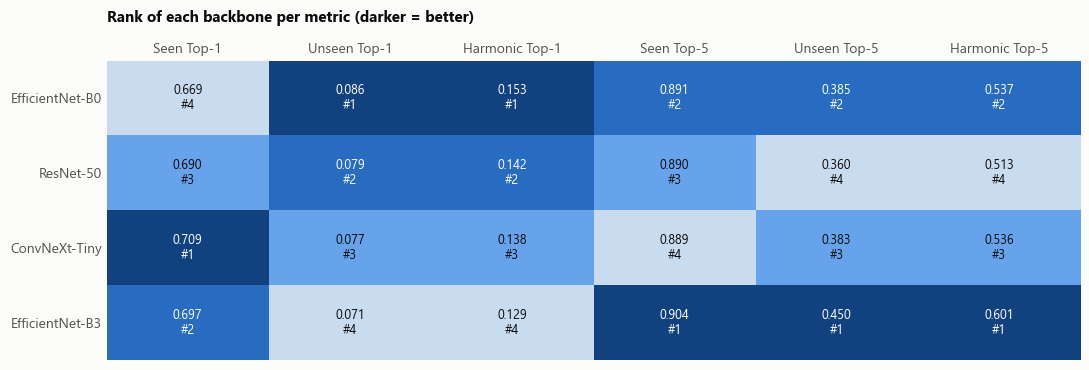

In [17]:
# rank grid: every metric at a glance (1 = best). Colour = rank, text = value.
vals = lb.values
ranks = (-vals).argsort(0).argsort(0) + 1
n = len(present)
fig, ax = plt.subplots(figsize=(11, 0.55 * n + 1.6))
ax.imshow((n - ranks) / max(n - 1, 1), cmap=BLUES, vmin=-0.15, vmax=1.1, aspect="auto")
for (r, c), v in np.ndenumerate(vals):
    ax.text(c, r, f"{v:.3f}\n#{ranks[r, c]}", ha="center", va="center", fontsize=9,
            color="white" if ranks[r, c] <= max(1, n // 2) else INK)
ax.set_xticks(range(len(METRICS)), [LABEL[m] for m in METRICS]); ax.set_yticks(range(n), lb.index)
ax.tick_params(colors=INK2, length=0); ax.grid(False); ax.xaxis.tick_top()
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Rank of each backbone per metric (darker = better)", pad=28)
fig.tight_layout(); plt.show()

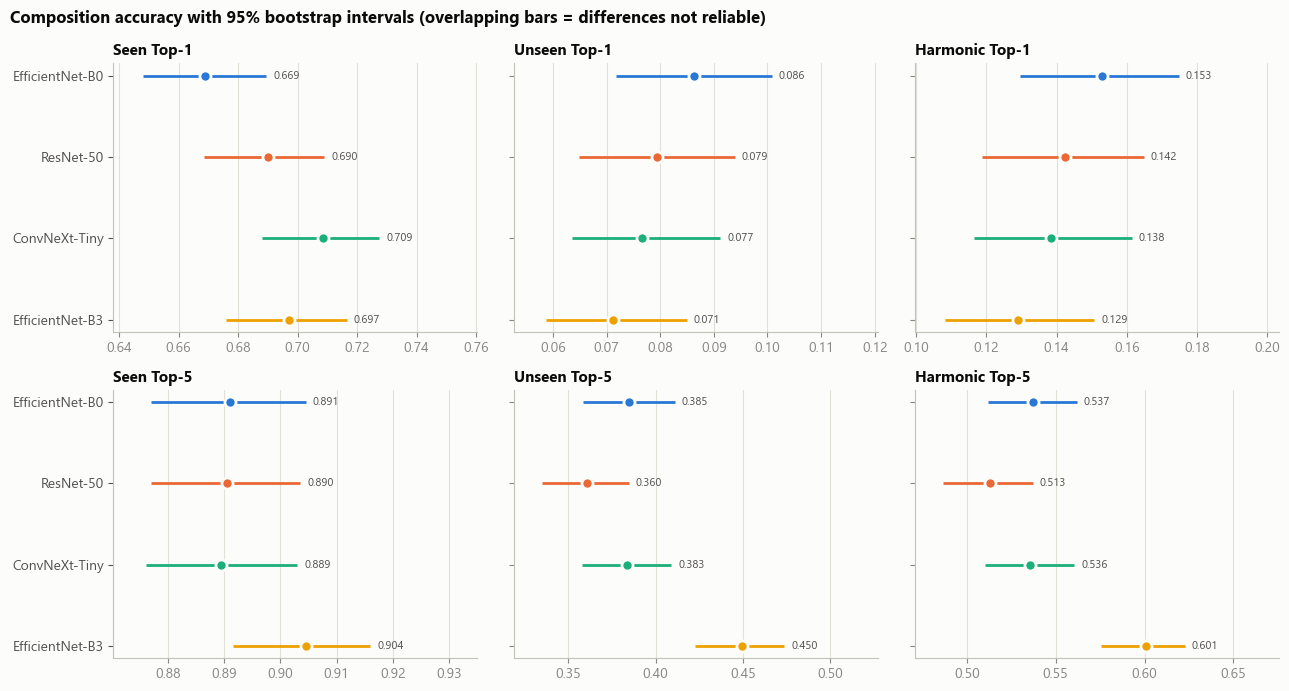

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(13, 0.5 * len(present) * 2 + 3), sharey=True)
for ax, m in zip(axes.flat, METRICS):
    for i, b in enumerate(present):
        lo, hi = ci((FT, b), m)
        ax.hlines(i, lo, hi, color=COLOR[b], linewidth=2)
        ax.plot(point[FT, b][m], i, "o", color=COLOR[b], markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(f"{point[FT, b][m]:.3f}", (hi, i), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK2)
    ax.set_title(LABEL[m]); ax.grid(True, axis="x"); ax.grid(False, axis="y")
    lo_all = min(ci((FT, b), m)[0] for b in present); hi_all = max(ci((FT, b), m)[1] for b in present)
    pad = (hi_all - lo_all) * 0.35 + 0.005
    ax.set_xlim(lo_all - pad * 0.3, hi_all + pad)
axes[0, 0].set_yticks(range(len(present)), [NAME[b] for b in present]); axes[0, 0].invert_yaxis()
for ax in axes[:, 0]:
    ax.tick_params(axis="y", colors=INK2)
fig.suptitle("Composition accuracy with 95% bootstrap intervals (overlapping bars = differences not reliable)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

## 3. Accuracy as more guesses are allowed (Top-k)

Fraction of test images whose true composition is among the backbone's top *k* guesses. If the lines cross,
the "best" backbone depends on how many guesses the application can show.

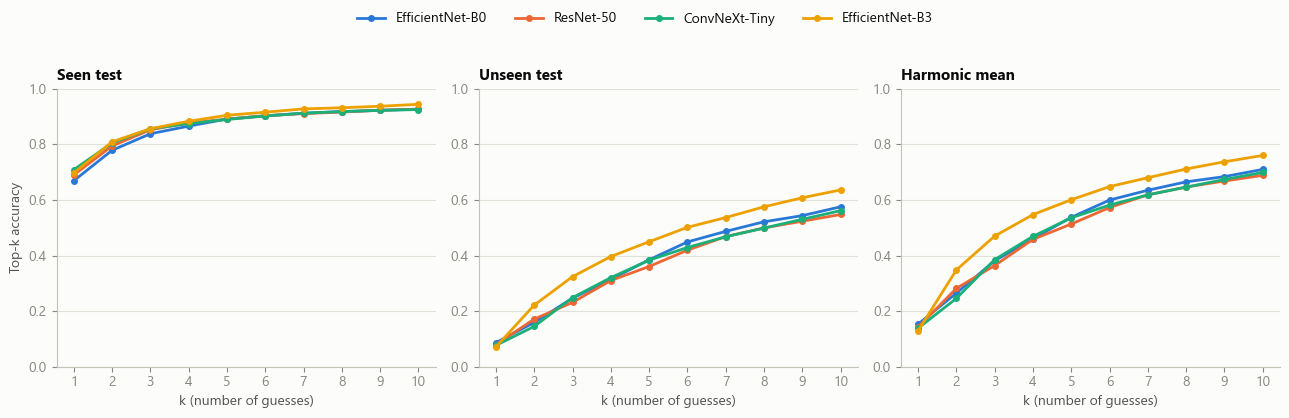

In [19]:
K = np.arange(1, 11)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for b in present:
    s_k = np.array([(R[FT, b, "seen"] < k).mean() for k in K])
    u_k = np.array([(R[FT, b, "unseen"] < k).mean() for k in K])
    for ax, v in zip(axes, [s_k, u_k, hm(s_k, u_k)]):
        ax.plot(K, v, color=COLOR[b], marker="o", markersize=4, label=NAME[b])
for ax, t in zip(axes, ["Seen test", "Unseen test", "Harmonic mean"]):
    ax.set_title(t); ax.set_xlabel("k (number of guesses)"); ax.set_xticks(K); ax.set_ylim(0, 1)
axes[0].set_ylabel("Top-k accuracy")
top_legend(fig, axes[0], top=0.88); plt.show()

## 4. Untouched ImageNet weights vs fine-tuning

**Frozen** = the ImageNet weights exactly as downloaded, with only a linear classifier trained on top
(`linear_probe.py --save_runs runs/frozen`). **Fine-tuned** = all layers trained on our images (`train.py`).
This shows how much of each backbone's result comes from its pretrained features and how much from training.

Seen Top-1            Unseen Top-1            Harmonic Top-1  \
                    frozen fine-tuned       frozen fine-tuned         frozen   
EfficientNet-B0      0.571      0.669        0.035      0.086          0.065   
ResNet-50            0.522      0.690        0.035      0.079          0.066   
ConvNeXt-Tiny        0.592      0.708        0.064      0.077          0.115   
EfficientNet-B3      0.574      0.697        0.048      0.071          0.088   

                           Harmonic Top-5             
                fine-tuned         frozen fine-tuned  
EfficientNet-B0      0.153          0.414      0.537  
ResNet-50            0.142          0.356      0.513  
ConvNeXt-Tiny        0.138          0.442      0.536  
EfficientNet-B3      0.129          0.420      0.601

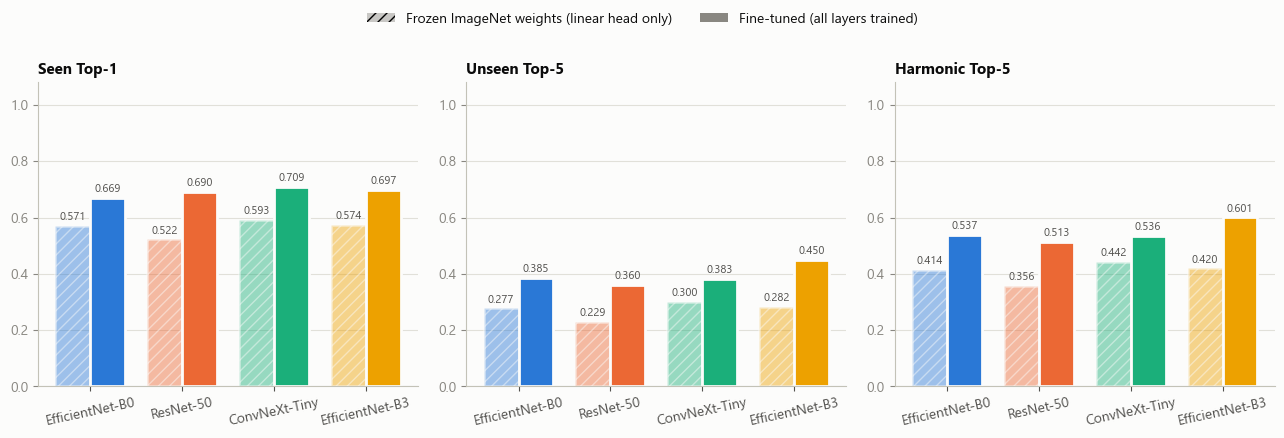

**Independent model seen-test Top-1, frozen vs fine-tuned**

crop            disease           
                frozen fine-tuned  frozen fine-tuned
EfficientNet-B0  0.835      0.898   0.588      0.674
ResNet-50        0.823      0.903   0.540      0.698
ConvNeXt-Tiny    0.878      0.908   0.597      0.716
EfficientNet-B3  0.856      0.913   0.588      0.703

In [20]:
if not frozen_present:
    print("No frozen runs found. Run: python linear_probe.py --img_dir DPD_Small_Dataset "
          "--models efficientnet_b0 resnet50 convnext_tiny efficientnet_b3 --save_runs runs/frozen")
else:
    both = [b for b in present if b in frozen_present]
    tbl = pd.DataFrame({(LABEL[m], meth): {NAME[b]: point[(meth, b)][m] for b in both}
                        for m in ["seen_top1", "unseen_top1", "harmonic_top1", "harmonic_top5"]
                        for meth in ("frozen", FT)})
    display(tbl.round(3))

    show = ["seen_top1", "unseen_top5", "harmonic_top5"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
    w = 0.38
    for ax, m in zip(axes, show):
        x = np.arange(len(both))
        for j, (meth, kw) in enumerate([("frozen", dict(alpha=0.45, hatch="///")), (FT, {})]):
            bars = ax.bar(x + (j - 0.5) * w, [point[(meth, b)][m] for b in both], w,
                          color=[COLOR[b] for b in both], edgecolor=SURFACE, linewidth=2, **kw)
            bar_labels(ax, bars)
        ax.set_xticks(x, [NAME[b] for b in both], rotation=12); ax.tick_params(axis="x", colors=INK2)
        ax.set_ylim(0, 1.08); ax.set_title(LABEL[m])
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.legend(handles=[Patch(facecolor=MUTED, alpha=0.45, hatch="///", label="Frozen ImageNet weights (linear head only)"),
                        Patch(facecolor=MUTED, label="Fine-tuned (all layers trained)")], loc="upper center", ncol=2)
    plt.show()

    task_tbl = pd.DataFrame({(task, meth): {NAME[b]: best.loc[(meth, b, task), "seen_top1"] for b in both}
                             for task in ("crop", "disease") for meth in ("frozen", FT)})
    display(Markdown("**Independent model seen-test Top-1, frozen vs fine-tuned**"))
    display(task_tbl.round(3))

## 5. Cost: size, training time and speed

Parameters are per model (each backbone needs two: crop + disease). Training time is for both models but laptop timings are noisy (other programs, heat), so treat
small differences loosely. Inference speed is measured live on this machine when a GPU is available.

In [21]:
MEASURE_SPEED = True   # set False to skip (takes ~30 s on a GPU)
speed = {}
if MEASURE_SPEED:
    import torch
    from torchvision import models
    from train import DEFAULT_SIZE
    if torch.cuda.is_available():
        for b in present:
            m = getattr(models, b)(weights=None).cuda().eval()
            x = torch.randn(64, 3, DEFAULT_SIZE.get(b, 224), DEFAULT_SIZE.get(b, 224), device="cuda")
            with torch.no_grad(), torch.autocast("cuda"):
                for _ in range(5): m(x)
                torch.cuda.synchronize(); t0 = time.time()
                for _ in range(20): m(x)
                torch.cuda.synchronize()
            speed[b] = 64 * 20 / (time.time() - t0)
            del m, x; torch.cuda.empty_cache()
    else:
        print("no GPU: speed test skipped")

cost = pd.DataFrame({NAME[b]: {
    "params per model (M)": best.loc[(FT, b, "crop"), "params_M"],
    "image size": int(best.loc[(FT, b, "crop"), "img_size"]),
    "s / epoch (crop)": best.loc[(FT, b, "crop"), "sec_per_epoch"],
    "s / epoch (disease)": best.loc[(FT, b, "disease"), "sec_per_epoch"],
    "train time, both models (min)": best.loc[(FT, b, "crop"), "train_min"] + best.loc[(FT, b, "disease"), "train_min"],
    "inference img/s (one model)": speed.get(b, np.nan),
    "Harmonic Top-1": point[FT, b]["harmonic_top1"], "Harmonic Top-5": point[FT, b]["harmonic_top5"]}
    for b in present}).T
display(cost.astype(float).round(3))

,params per model (M),image size,s / epoch (crop),s / epoch (disease),"train time, both models (min)",inference img/s (one model),Harmonic Top-1,Harmonic Top-5
EfficientNet-B0,4.1,224.0,63.667,66.733,32.600,1664.768,0.153,0.537
ResNet-50,23.6,224.0,67.400,64.133,32.883,760.416,0.142,0.513
ConvNeXt-Tiny,27.9,224.0,68.400,67.600,34.000,670.337,0.138,0.536
EfficientNet-B3,10.8,300.0,238.467,95.667,83.533,410.449,0.129,0.601


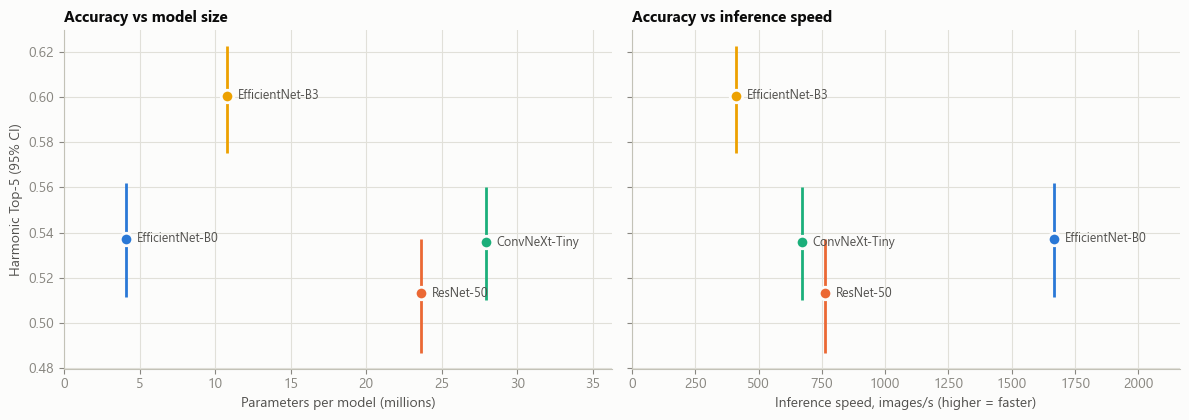

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
xs = [("params per model (M)", "Parameters per model (millions)"),
      ("inference img/s (one model)", "Inference speed, images/s (higher = faster)") if speed else
      ("train time, both models (min)", "Training time, both models (minutes)")]
for ax, (col, xl) in zip(axes, xs):
    for b in present:
        x, y = cost.loc[NAME[b], col], point[FT, b]["harmonic_top5"]
        lo, hi = ci((FT, b), "harmonic_top5")
        ax.vlines(x, lo, hi, color=COLOR[b], linewidth=2)
        ax.plot(x, y, "o", color=COLOR[b], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(NAME[b], (x, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
    ax.set_xlabel(xl); ax.grid(True, axis="both")
    ax.set_xlim(0, cost[col].max() * 1.3)
axes[0].set_ylabel("Harmonic Top-5 (95% CI)")
axes[0].set_title("Accuracy vs model size")
axes[1].set_title("Accuracy vs inference speed" if speed else "Accuracy vs training time")
fig.tight_layout(); plt.show()

## 6. The two independent models on their own

Each model on its own task, before combining. The unseen-test drop is much larger for the **disease** model.

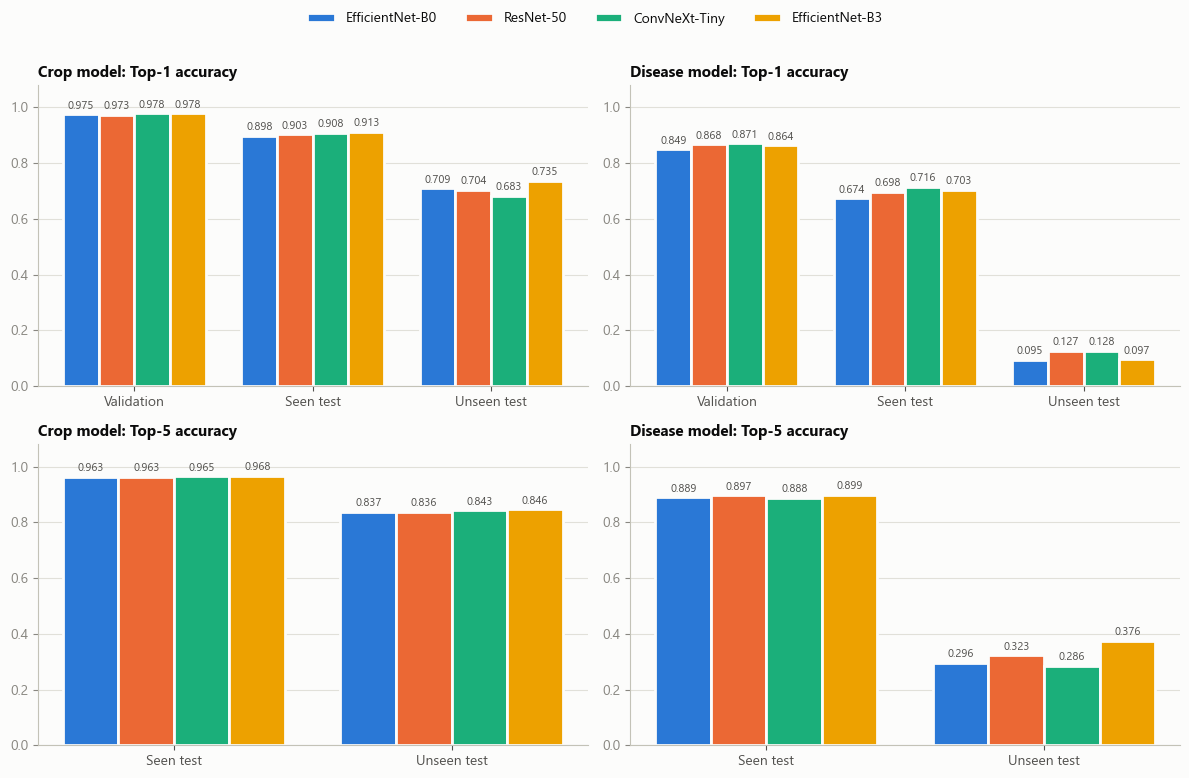

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.8))
for j, task in enumerate(["crop", "disease"]):
    for i, k in enumerate(["top1", "top5"]):
        groups = ["Validation", "Seen test", "Unseen test"] if k == "top1" else ["Seen test", "Unseen test"]
        vals = {b: ([best.loc[(FT, b, task), "val_top1"]] if k == "top1" else []) +
                   [best.loc[(FT, b, task), f"seen_{k}"], best.loc[(FT, b, task), f"unseen_{k}"]] for b in present}
        grouped_bars(axes[i, j], groups, vals, present)
        axes[i, j].set_title(f"{task.capitalize()} model: {'Top-1' if k == 'top1' else 'Top-5'} accuracy")
top_legend(fig, axes[0, 0], top=0.94); plt.show()

## 7. Training curves

Validation Top-1 per epoch (the best epoch is the checkpoint that was tested) and training loss.

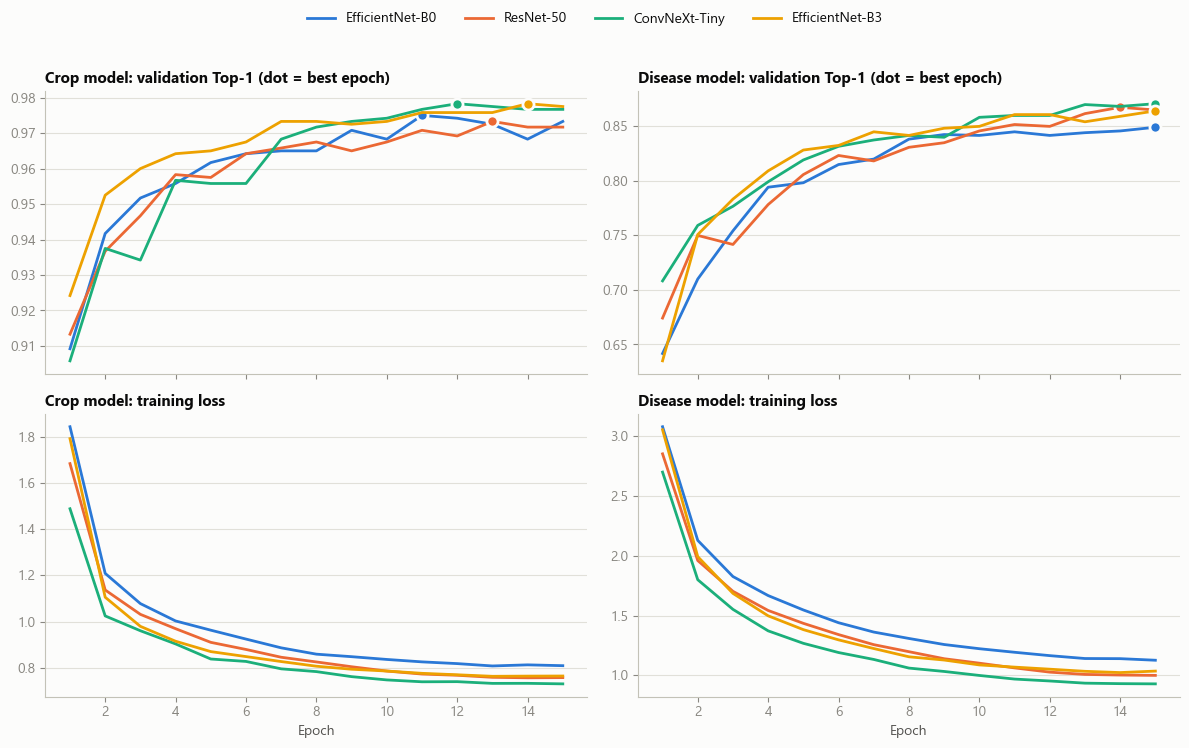

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for j, task in enumerate(["crop", "disease"]):
    for b in present:
        h = best.loc[(FT, b, task), "history"]
        axes[0, j].plot(h["epoch"], h["val_top1"], color=COLOR[b], label=NAME[b])
        axes[1, j].plot(h["epoch"], h["train_loss"], color=COLOR[b], label=NAME[b])
        i = h["val_top1"].idxmax()
        axes[0, j].plot(h.loc[i, "epoch"], h.loc[i, "val_top1"], "o", color=COLOR[b], markersize=8,
                        markeredgecolor=SURFACE, markeredgewidth=2)
    axes[0, j].set_title(f"{task.capitalize()} model: validation Top-1 (dot = best epoch)")
    axes[1, j].set_title(f"{task.capitalize()} model: training loss")
    axes[1, j].set_xlabel("Epoch")
top_legend(fig, axes[0, 0], top=0.93); plt.show()

## 8. Where do composition errors come from?

Each test image's top composition, split by whether its crop and its disease are right.

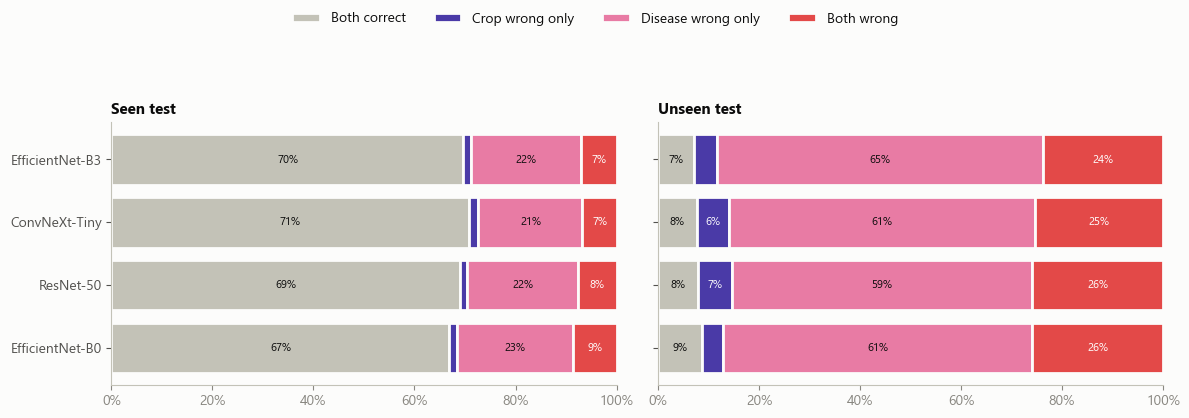

In [25]:
PARTS = [("Both correct", "#c3c2b7"), ("Crop wrong only", "#4a3aa7"),
         ("Disease wrong only", "#e87ba4"), ("Both wrong", "#e34948")]
comp_crop = pd.Series(crop_idx, index=comp_ids); comp_dis = pd.Series(dis_idx, index=comp_ids)

fig, axes = plt.subplots(1, 2, figsize=(12, 0.6 * len(present) + 1.8), sharey=True)
for ax, (split, df) in zip(axes, [("seen", se), ("unseen", un)]):
    for i, b in enumerate(present):
        pred = comp_ids[S[b, split].argmax(1)]
        cok = comp_crop[pred].values == df["crop"].values
        dok = comp_dis[pred].values == df["disease"].values
        fr = [np.mean(cok & dok), np.mean(~cok & dok), np.mean(cok & ~dok), np.mean(~cok & ~dok)]
        left = 0
        for (lab, col), f in zip(PARTS, fr):
            ax.barh(i, f, left=left, color=col, edgecolor=SURFACE, linewidth=2, label=lab if i == 0 else None)
            if f >= 0.06:
                ax.text(left + f / 2, i, f"{f:.0%}", ha="center", va="center", fontsize=8,
                        color=INK if col in ("#c3c2b7", "#e87ba4") else "white")
            left += f
    ax.set_yticks(range(len(present)), [NAME[b] for b in present]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.grid(False); ax.set_title(f"{split.capitalize()} test"); ax.tick_params(axis="y", colors=INK2)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
top_legend(fig, axes[0], top=0.8); plt.show()

## 9. Per unseen composition

Top-1 accuracy on each of the 10 unseen crop + disease pairs (test images in brackets).

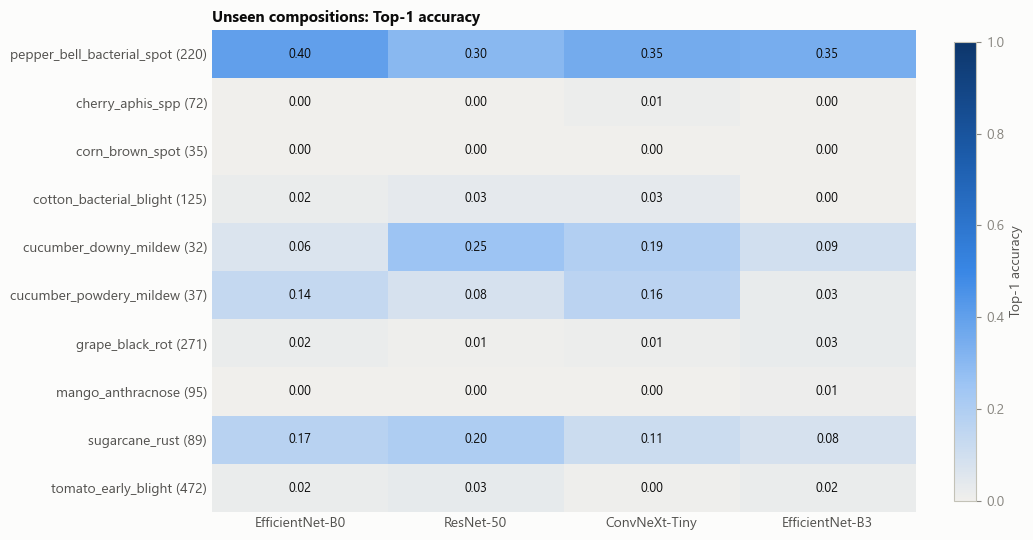

In [26]:
un_comps = sorted(un["comp"].unique())
y_un = un["comp"].values
H = pd.DataFrame({NAME[b]: [float((comp_ids[S[b, "unseen"].argmax(1)][y_un == c] == c).mean()) for c in un_comps]
                  for b in present},
                 index=[f"{comp_name[c]} ({(y_un == c).sum()})" for c in un_comps])

fig, ax = plt.subplots(figsize=(1.6 * len(present) + 4, 5.5))
im = ax.imshow(H.values, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(H.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else INK)
ax.set_xticks(range(H.shape[1]), H.columns); ax.set_yticks(range(H.shape[0]), H.index)
ax.tick_params(colors=INK2, length=0); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, label="Top-1 accuracy")
ax.set_title("Unseen compositions: Top-1 accuracy")
fig.tight_layout(); plt.show()

## 10. Is the disease model leaning on the crop?

On the unseen test the true disease never appeared on that crop in training. If a disease model has learned
"this crop -> its usual diseases", many of its wrong answers will be diseases that the crop *did* have in training.

In [27]:
seen_pairs = set(zip(tr["crop"], tr["disease"]))
rows = []
for b in present:
    pred = np.load(best.loc[(FT, b, "disease"), "dir"] / "probs_unseen.npy").argmax(1)
    right = pred == un["disease"].values
    usual = np.array([(c, p) in seen_pairs for c, p in zip(un["crop"], pred)])
    rows.append({"backbone": NAME[b], "disease correct": right.mean(),
                 "wrong: a disease this crop had in training": (usual & ~right).mean(),
                 "wrong: other disease": (~usual & ~right).mean()})
display(pd.DataFrame(rows).set_index("backbone").round(3))

pred = np.load(best.loc[(FT, BEST, "disease"), "dir"] / "probs_unseen.npy").argmax(1)
print(f"{NAME[BEST]}: most frequent disease prediction per unseen composition")
display(pd.DataFrame([{"composition": comp_name[c],
                       "train imgs of the true disease": int((tr["disease"] == un.loc[un["comp"] == c, "disease"].iloc[0]).sum()),
                       "most-predicted disease": dis_name[pd.Series(pred[(un["comp"] == c).values]).mode()[0]]}
                      for c in un_comps]).set_index("composition"))

,disease correct,wrong: a disease this crop had in training,wrong: other disease
backbone,,,
EfficientNet-B0,0.095,0.526,0.379
ResNet-50,0.127,0.514,0.359
ConvNeXt-Tiny,0.128,0.537,0.335
EfficientNet-B3,0.097,0.564,0.340


ConvNeXt-Tiny: most frequent disease prediction per unseen composition


,train imgs of the true disease,most-predicted disease
composition,,
pepper_bell_bacterial_spot,188,bacterial_spot
cherry_aphis_spp,7,erwinia_amylovora
corn_brown_spot,261,lethal_necrosis
cotton_bacterial_blight,147,target_spot
cucumber_downy_mildew,69,anthracnose
cucumber_powdery_mildew,226,powdery_mildew
grape_black_rot,36,esca
mango_anthracnose,51,gall_midge
sugarcane_rust,297,red_rot


## 11. Does class size explain disease errors?

Disease classes are very imbalanced (one has a single training image). Seen-test disease accuracy per backbone,
grouped by how many training images the class has (weighted by test images).

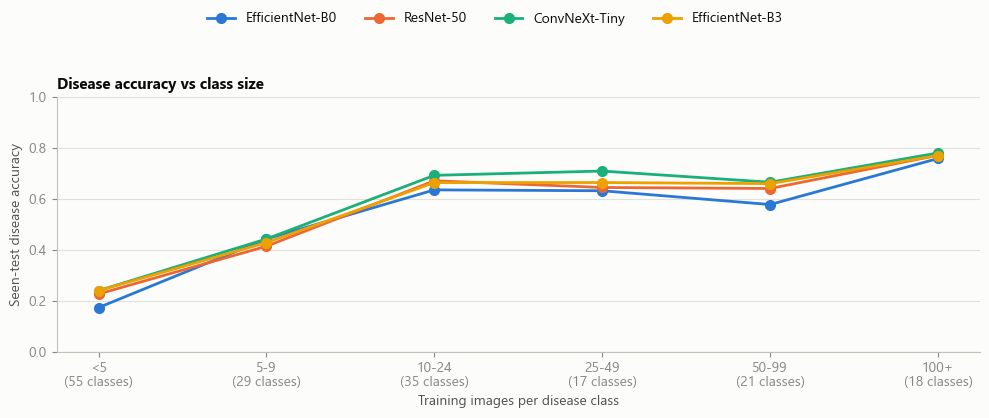

,EfficientNet-B0,ResNet-50,ConvNeXt-Tiny,EfficientNet-B3,test images,disease classes
<5,0.173,0.227,0.240,0.240,75,55
5-9,0.443,0.414,0.443,0.429,70,29
10-24,0.636,0.671,0.693,0.664,140,35
25-49,0.632,0.645,0.710,0.665,155,17
50-99,0.578,0.641,0.666,0.660,365,21
100+,0.759,0.772,0.781,0.771,1195,18


In [28]:
bins = [0, 5, 10, 25, 50, 100, 10_000]
labels = ["<5", "5-9", "10-24", "25-49", "50-99", "100+"]
n_train = tr["disease"].value_counts()
cls_bin = pd.cut(se["disease"].map(n_train).fillna(0), bins, right=False, labels=labels)
acc_bin = pd.DataFrame({NAME[b]: pd.Series(np.load(best.loc[(FT, b, "disease"), "dir"] / "probs_seen.npy").argmax(1)
                                           == se["disease"].values).groupby(cls_bin.values, observed=False).mean()
                        for b in present})
acc_bin["test images"] = cls_bin.value_counts().reindex(labels).values
acc_bin["disease classes"] = pd.cut(n_train, bins, right=False, labels=labels).value_counts().reindex(labels).values

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(labels))
for b in present:
    ax.plot(x, acc_bin[NAME[b]], color=COLOR[b], marker="o", markersize=7, label=NAME[b])
ax.set_xticks(x, [f"{l}\n({n} classes)" for l, n in zip(labels, acc_bin["disease classes"])])
ax.set_xlabel("Training images per disease class"); ax.set_ylabel("Seen-test disease accuracy"); ax.set_ylim(0, 1)
ax.set_title("Disease accuracy vs class size")
top_legend(fig, ax, top=0.86); plt.show()
display(acc_bin.round(3))

## 12. Most confused seen compositions and example unseen mistakes (`BEST` backbone)

In [29]:
y_se = se["comp"].values
pred_se = comp_ids[S[BEST, "seen"].argmax(1)]
wrong = pd.DataFrame({"true": comp_name[y_se].values, "predicted": comp_name[pred_se].values})[pred_se != y_se]
print(f"{NAME[BEST]}: {len(wrong)} of {len(y_se)} seen-test images wrong")
display(wrong.value_counts().rename("images").head(15).to_frame())

ConvNeXt-Tiny: 583 of 2000 seen-test images wrong


,,images
true,predicted,
paddy_healthy,paddy_blast,16
soybean_caterpillar,soybean_diabrotica_speciosa,12
tomato_septoria_leaf_spot,tomato_verticulium_wilt,10
tomato_bacterial_spot,tomato_septoria_leaf_spot,9
soybean_healthy,soybean_caterpillar,8
cassava_mosaic,cassava_healthy,7
apple_marssonina_blotch,apple_alternaria_leaf_spot,7
soybean_healthy,soybean_diabrotica_speciosa,7
wheat_stripe_rust,wheat_rust,7


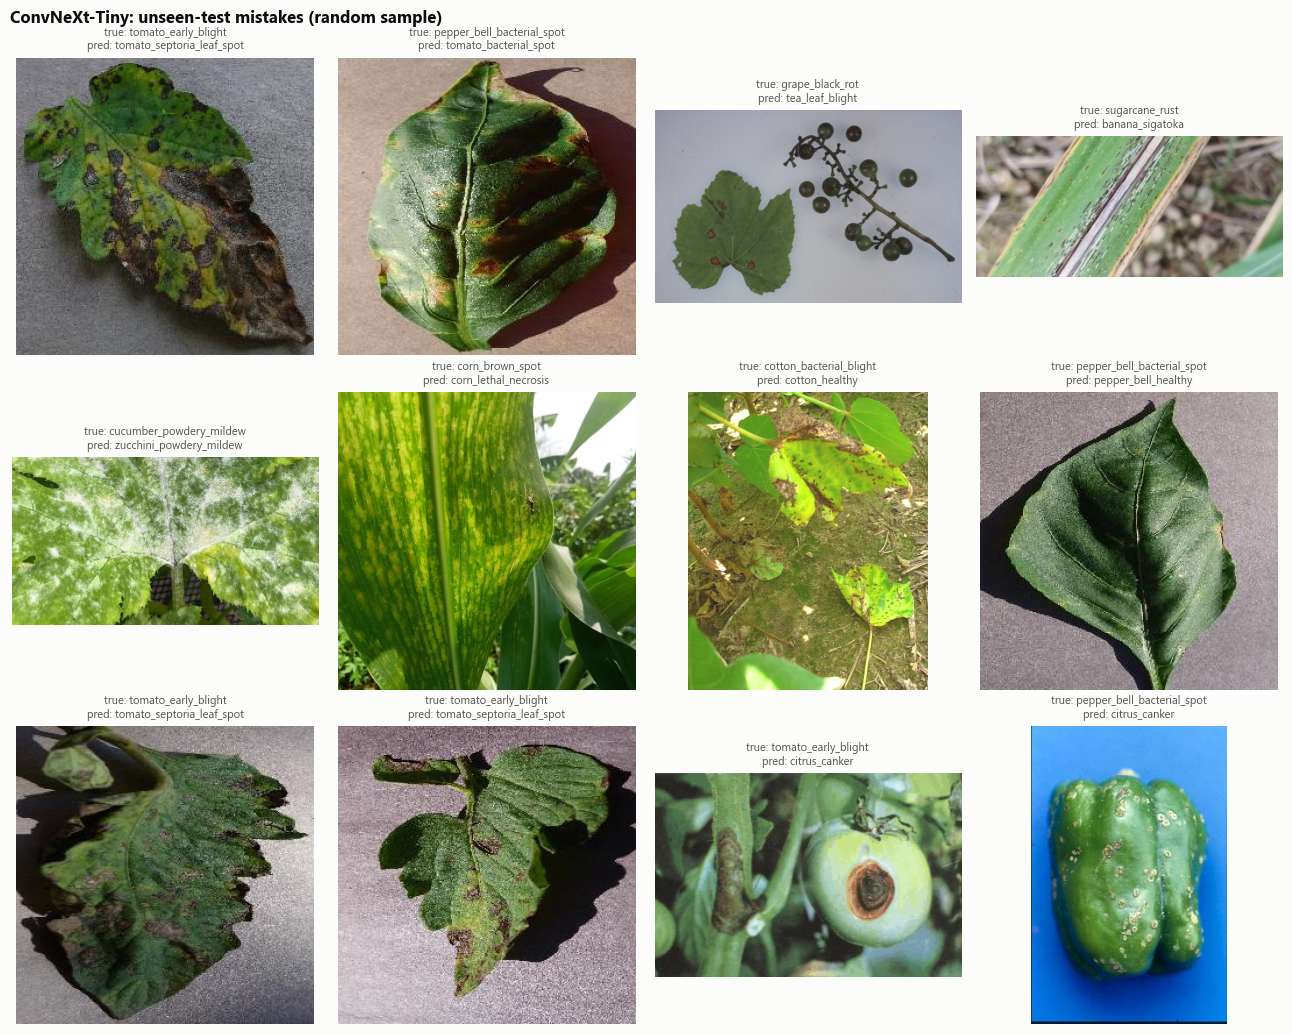

In [30]:
pred_un = comp_ids[S[BEST, "unseen"].argmax(1)]
idx = np.flatnonzero(pred_un != y_un)
pick = np.random.default_rng(0).choice(idx, size=min(12, len(idx)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(13, 10.5))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, pick):
    ax.imshow(Image.open(IMG_DIR / un["file"].iloc[i]).convert("RGB"))
    ax.set_title(f"true: {comp_name[y_un[i]]}\npred: {comp_name[pred_un[i]]}", fontsize=8,
                 fontweight="normal", loc="center", color=INK2)
fig.suptitle(f"{NAME[BEST]}: unseen-test mistakes (random sample)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()